# Cyber Crime Data Analysis (India, 2016–2018)
This notebook analyses cyber-crime cases reported in Indian States and Union Territories.

## 1. Setup & Data Loading
First we import all the libraries we need.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sqlite3

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

### Load the dataset
The file ends in `.csv`, but the values are separated by **tabs**, so we use `sep="\t"`.
We also rename the columns to short, simple names (the originals are long and have special characters).

In [2]:
df = pd.read_csv("cyber_crimes.csv", sep="\t")

df.columns = ["S_No", "Category", "State_UT", "Crimes_2016", "Crimes_2017",
              "Crimes_2018", "Share_2018", "Population_Lakhs", "Rate_2018"]

df.head()

,S_No,Category,State_UT,Crimes_2016,Crimes_2017,Crimes_2018,Share_2018,Population_Lakhs,Rate_2018
0,1,State,Andhra Pradesh,616,931,1207,4.4,520.3,2.3
1,2,State,Arunachal Pradesh,4,1,7,0.0,14.9,0.5
2,3,State,Assam,696,1120,2022,7.4,340.4,5.9
3,4,State,Bihar,309,433,374,1.4,1183.3,0.3
4,5,State,Chhattisgarh,90,171,139,0.5,284.7,0.5


### SQLite database demo
We create an in-memory database, store our data in a table, and read it back using SQL queries.

In [3]:
# Create an in-memory database
conn = sqlite3.connect(":memory:")

# Save the DataFrame as a table called cyber_crimes
df.to_sql("cyber_crimes", conn, index=False, if_exists="replace")

# Simple query: first 5 rows
query1 = "SELECT * FROM cyber_crimes LIMIT 5"
print(pd.read_sql_query(query1, conn))

# A slightly more useful query: top 5 states by 2018 cases (skipping total rows)
query2 = """
SELECT State_UT, Crimes_2018
FROM cyber_crimes
WHERE Category = 'State' AND State_UT NOT LIKE 'Total%'
ORDER BY Crimes_2018 DESC
LIMIT 5
"""
print(pd.read_sql_query(query2, conn))

  S_No Category           State_UT  Crimes_2016  Crimes_2017  Crimes_2018  \
0    1    State     Andhra Pradesh          616          931         1207   
1    2    State  Arunachal Pradesh            4            1            7   
2    3    State              Assam          696         1120         2022   
3    4    State              Bihar          309          433          374   
4    5    State       Chhattisgarh           90          171          139   

   Share_2018  Population_Lakhs  Rate_2018  
0         4.4             520.3        2.3  
1         0.0              14.9        0.5  
2         7.4             340.4        5.9  
3         1.4            1183.3        0.3  
4         0.5             284.7        0.5  
         State_UT  Crimes_2018
0   Uttar Pradesh         6280
1       Karnataka         5839
2     Maharashtra         3511
3           Assam         2022
4  Andhra Pradesh         1207


## 2. Data Understanding & Summary Statistics
Let's look at the structure of the data: first rows, data types, size and column names.

In [4]:
print("First 5 rows:")
display(df.head())

print("\nDataset info:")
df.info()

print("\nShape (rows, columns):", df.shape)

print("\nColumn names:")
print(df.columns)

First 5 rows:


,S_No,Category,State_UT,Crimes_2016,Crimes_2017,Crimes_2018,Share_2018,Population_Lakhs,Rate_2018
0,1,State,Andhra Pradesh,616,931,1207,4.4,520.3,2.3
1,2,State,Arunachal Pradesh,4,1,7,0.0,14.9,0.5
2,3,State,Assam,696,1120,2022,7.4,340.4,5.9
3,4,State,Bihar,309,433,374,1.4,1183.3,0.3
4,5,State,Chhattisgarh,90,171,139,0.5,284.7,0.5



Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   S_No              39 non-null     object 
 1   Category          39 non-null     object 
 2   State_UT          39 non-null     object 
 3   Crimes_2016       39 non-null     int64  
 4   Crimes_2017       39 non-null     int64  
 5   Crimes_2018       39 non-null     int64  
 6   Share_2018        39 non-null     float64
 7   Population_Lakhs  39 non-null     float64
 8   Rate_2018         39 non-null     float64
dtypes: float64(3), int64(3), object(3)
memory usage: 2.9+ KB

Shape (rows, columns): (39, 9)

Column names:
Index(['S_No', 'Category', 'State_UT', 'Crimes_2016', 'Crimes_2017',
       'Crimes_2018', 'Share_2018', 'Population_Lakhs', 'Rate_2018'],
      dtype='object')


### Summary statistics
`.describe()` gives mean, std, min, max etc. for numbers. `include='object'` gives counts for text columns.
Note: these numbers still include the "Total" rows, which we remove in the next section.

In [6]:
print("Numerical columns:")
display(df.describe())

print("Categorical columns:")
display(df.describe(include="object"))

Numerical columns:


,Crimes_2016,Crimes_2017,Crimes_2018,Share_2018,Population_Lakhs,Rate_2018
count,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000
mean,947.461538,1676.615385,2096.000000,7.689744,1017.987179,1.689744
std,2724.974532,4832.658115,6065.161416,22.257391,2885.991893,1.811193
min,0.000000,0.000000,0.000000,0.000000,0.700000,0.000000
25%,9.500000,11.500000,24.500000,0.100000,18.300000,0.500000
50%,102.000000,176.000000,239.000000,0.900000,284.000000,1.000000
75%,439.500000,772.000000,886.500000,3.250000,663.850000,2.200000
max,12317.000000,21796.000000,27248.000000,100.000000,13233.800000,8.900000


Categorical columns:


,S_No,Category,State_UT
count,39,39,39
unique,39,3,39
top,1,State,Andhra Pradesh
freq,1,30,1


## 3. Data Cleaning & Preprocessing
We check for duplicates and missing values, then remove the "Total" rows.

In [7]:
# Duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Missing values
print("\nMissing values per column:")
print(df.isnull().sum())

Duplicate rows: 0

Missing values per column:
S_No                0
Category            0
State_UT            0
Crimes_2016         0
Crimes_2017         0
Crimes_2018         0
Share_2018          0
Population_Lakhs    0
Rate_2018           0
dtype: int64


### Fill missing values
This dataset has no missing values, but the code below shows how to handle them:
numbers are filled with the **median**, text columns with the **mode** (most common value).

In [8]:
for col in df.columns:
    if df[col].dtype == "int64" or df[col].dtype == "float64":
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after filling:", df.isnull().sum().sum())

Missing values after filling: 0


### Remove the "Total" rows
Rows like "Total State(s)", "Total UT(s)" and "Total (All India)" are sums of other rows.
If we keep them, they will look like huge outliers and spoil our analysis, so we drop them.

In [9]:
df = df[~df["State_UT"].str.contains("Total")]
df = df.reset_index(drop=True)

print("Shape after removing totals:", df.shape)
print(df["Category"].value_counts())

Shape after removing totals: (36, 9)
Category
State              29
Union Territory     7
Name: count, dtype: int64


## 4. Outlier Detection using Z-Score
Z-score = (value − mean) / standard deviation.
A value with |Z| > 3 is far from the average and is treated as an outlier.

In [10]:
num_cols = ["Crimes_2016", "Crimes_2017", "Crimes_2018",
            "Share_2018", "Population_Lakhs", "Rate_2018"]

z_scores = stats.zscore(df[num_cols])
z_df = pd.DataFrame(z_scores, columns=num_cols)

# Count outliers in each column
print("Number of outliers (|Z| > 3) per column:")
print((z_df.abs() > 3).sum())

Number of outliers (|Z| > 3) per column:
Crimes_2016         2
Crimes_2017         1
Crimes_2018         2
Share_2018          2
Population_Lakhs    1
Rate_2018           1
dtype: int64


In [11]:
# Which states are outliers for Crimes_2018 and Rate_2018?
outlier_rows = df[z_df["Crimes_2018"].abs() > 3]
print("Outliers in Crimes_2018:")
display(outlier_rows[["State_UT", "Crimes_2018"]])

outlier_rate = df[z_df["Rate_2018"].abs() > 3]
print("Outliers in Rate_2018:")
display(outlier_rate[["State_UT", "Rate_2018"]])

Outliers in Crimes_2018:


,State_UT,Crimes_2018
11,Karnataka,5839
26,Uttar Pradesh,6280


Outliers in Rate_2018:


,State_UT,Rate_2018
11,Karnataka,8.9


### Basic NumPy operations
We convert some columns into NumPy arrays and try mean, standard deviation, slicing, transpose and dot product.

In [12]:
# 1D array
crimes_2018 = df["Crimes_2018"].values
print("Mean of 2018 crimes:", np.mean(crimes_2018))
print("Std deviation of 2018 crimes:", np.std(crimes_2018))

# Slicing
print("First 5 values:", crimes_2018[:5])
print("Last 3 values:", crimes_2018[-3:])

# 2D array (matrix) from three columns
matrix = df[["Crimes_2016", "Crimes_2017", "Crimes_2018"]].values
print("\nMatrix shape:", matrix.shape)
print("Transpose shape:", matrix.T.shape)

# Dot product of transpose and matrix gives a 3x3 matrix
result = np.dot(matrix.T, matrix)
print("\nMatrix.T dot Matrix:")
print(result)

Mean of 2018 crimes: 756.8888888888889
Std deviation of 2018 crimes: 1461.1412354309023
First 5 values: [1207    7 2022  374  139]
Last 3 values: [189   4  14]

Matrix shape: (36, 3)
Transpose shape: (3, 36)

Matrix.T dot Matrix:
[[16929769 30022348 36872578]
 [30022348 55740262 71609416]
 [36872578 71609416 97481322]]


## 5. Data Visualizations
### 5.1 Matplotlib plots
**Line plot** – how the top 5 states changed from 2016 to 2018.

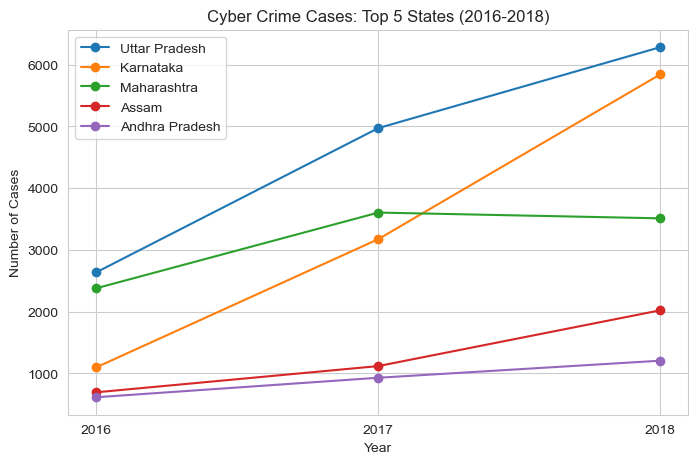

In [13]:
top5 = df.sort_values("Crimes_2018", ascending=False).head(5)

plt.figure(figsize=(8, 5))
for i in range(len(top5)):
    row = top5.iloc[i]
    plt.plot([2016, 2017, 2018],
             [row["Crimes_2016"], row["Crimes_2017"], row["Crimes_2018"]],
             marker="o", label=row["State_UT"])

plt.xticks([2016, 2017, 2018])
plt.title("Cyber Crime Cases: Top 5 States (2016-2018)")
plt.xlabel("Year")
plt.ylabel("Number of Cases")
plt.legend()
plt.show()

**Bar chart** – the 10 states/UTs with the most cases in 2018.

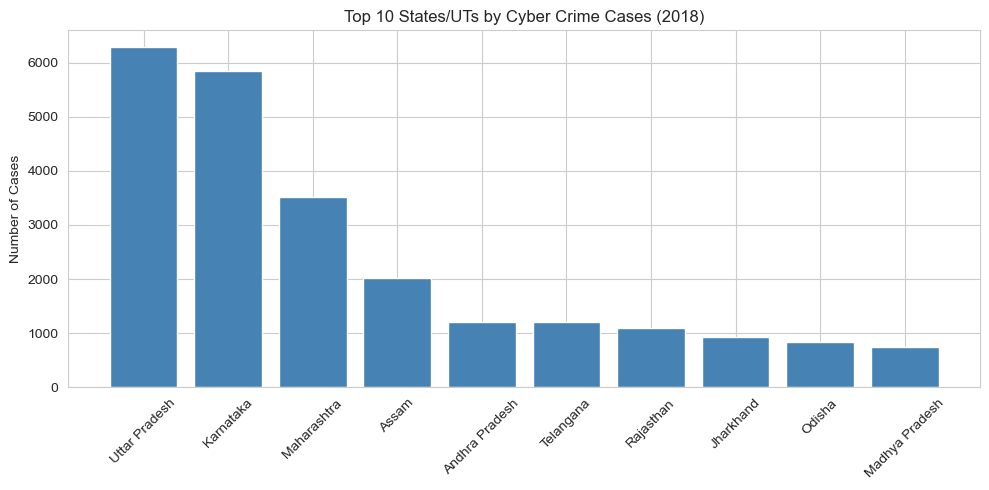

In [14]:
top10 = df.sort_values("Crimes_2018", ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.bar(top10["State_UT"], top10["Crimes_2018"], color="steelblue")
plt.xticks(rotation=45)
plt.title("Top 10 States/UTs by Cyber Crime Cases (2018)")
plt.ylabel("Number of Cases")
plt.tight_layout()
plt.show()

**Scatter plot** – does a bigger population mean more cyber crime?

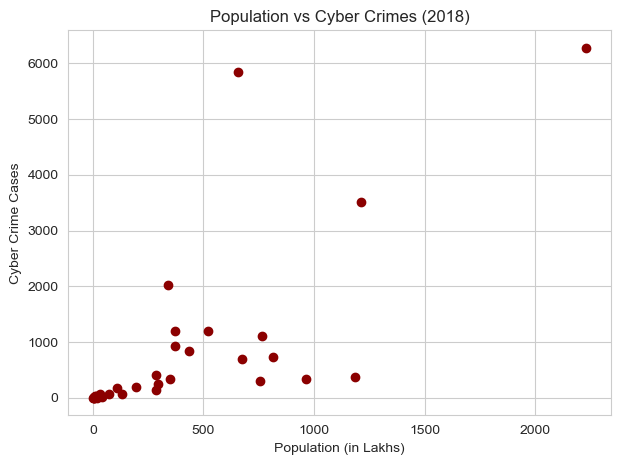

In [15]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Population_Lakhs"], df["Crimes_2018"], color="darkred")
plt.title("Population vs Cyber Crimes (2018)")
plt.xlabel("Population (in Lakhs)")
plt.ylabel("Cyber Crime Cases")
plt.show()

### 5.2 Seaborn plots
**Count plot** – how many States and Union Territories are in the data.

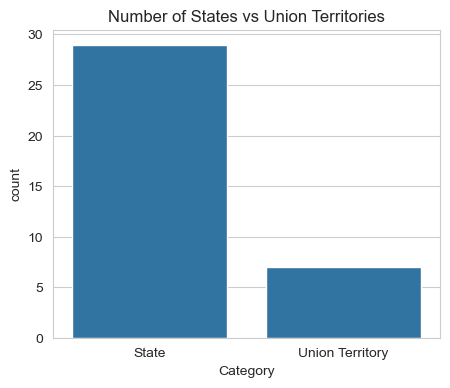

In [16]:
plt.figure(figsize=(5, 4))
sns.countplot(x="Category", data=df)
plt.title("Number of States vs Union Territories")
plt.show()

**Box plots** – dots beyond the whiskers are outliers (they match the Z-score results above).

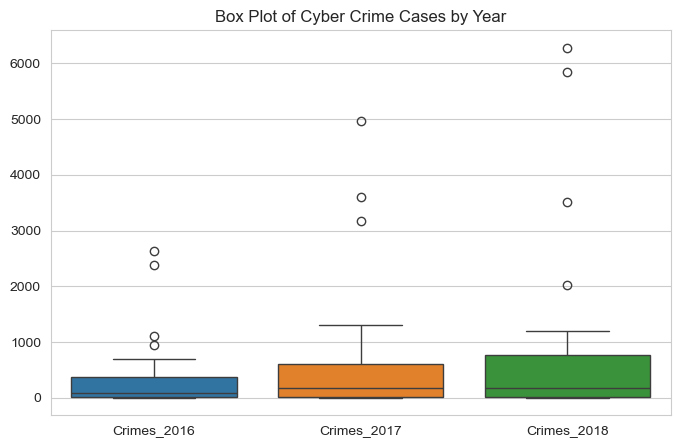

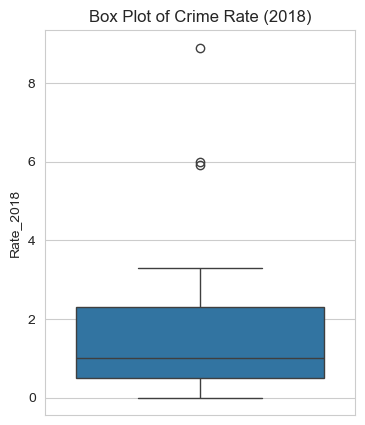

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[["Crimes_2016", "Crimes_2017", "Crimes_2018"]])
plt.title("Box Plot of Cyber Crime Cases by Year")
plt.show()

plt.figure(figsize=(4, 5))
sns.boxplot(y=df["Rate_2018"])
plt.title("Box Plot of Crime Rate (2018)")
plt.show()

**Heatmap** – shows how strongly the numeric columns are related.

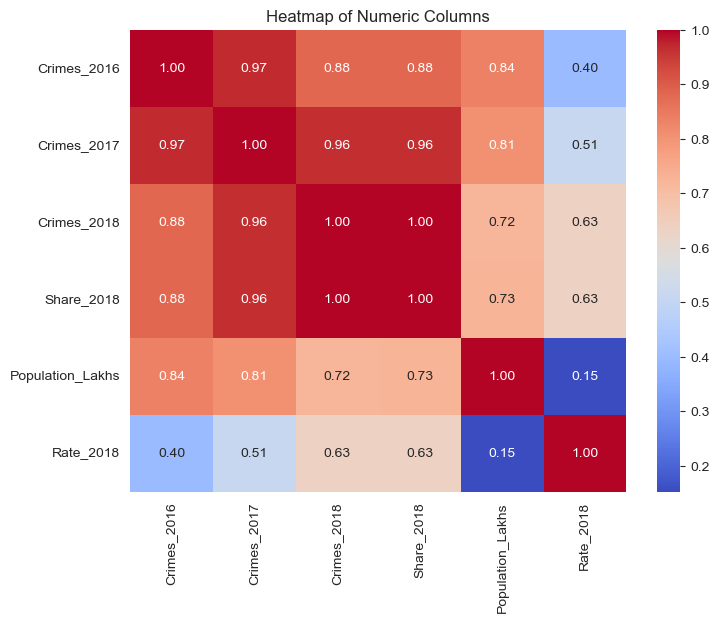

In [18]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heatmap of Numeric Columns")
plt.show()

### 5.3 Distribution analysis
Histograms with a KDE (smooth density) line show the shape of the data.

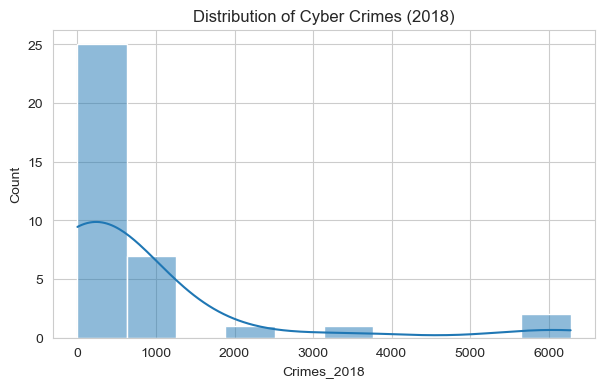

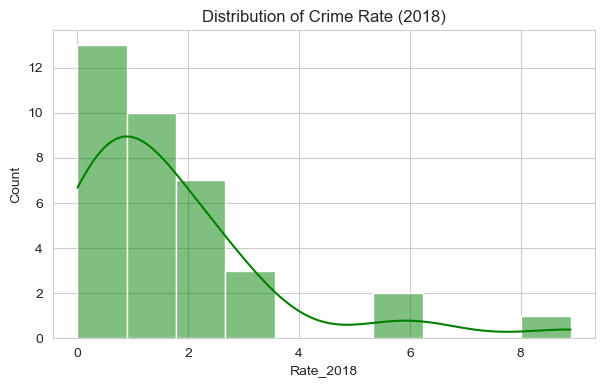

In [19]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Crimes_2018"], kde=True, bins=10)
plt.title("Distribution of Cyber Crimes (2018)")
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(df["Rate_2018"], kde=True, bins=10, color="green")
plt.title("Distribution of Crime Rate (2018)")
plt.show()

**Observation:** Both histograms are heavily right-skewed. Most states have low values and a few (like Karnataka and Uttar Pradesh) have very high values.

## 6. Statistical Analysis
### 6.1 Correlation analysis
Correlation ranges from -1 to +1. Values near +1 mean two columns increase together.

,Crimes_2016,Crimes_2017,Crimes_2018,Share_2018,Population_Lakhs,Rate_2018
Crimes_2016,1.000000,0.970172,0.881269,0.881563,0.836420,0.396685
Crimes_2017,0.970172,1.000000,0.963797,0.963955,0.807638,0.511180
Crimes_2018,0.881269,0.963797,1.000000,0.999989,0.724852,0.633553
Share_2018,0.881563,0.963955,0.999989,1.000000,0.725222,0.632999
Population_Lakhs,0.836420,0.807638,0.724852,0.725222,1.000000,0.151820
Rate_2018,0.396685,0.511180,0.633553,0.632999,0.151820,1.000000


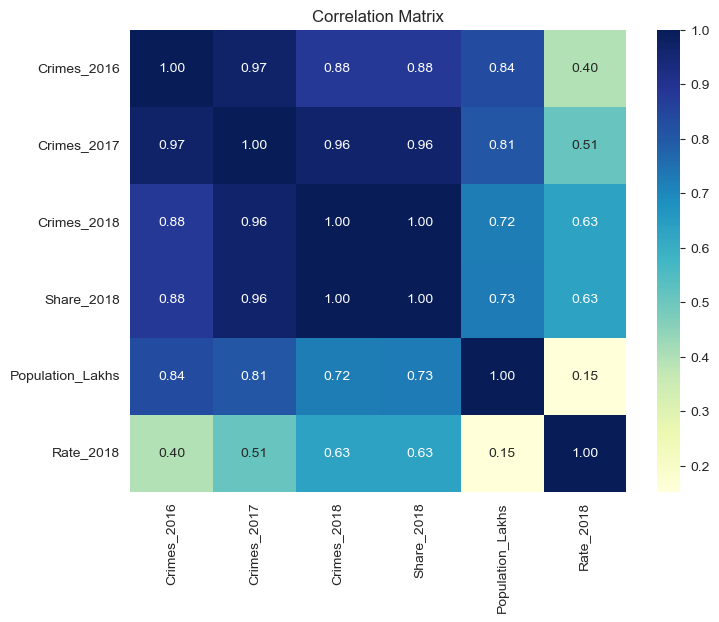

In [20]:
corr_matrix = df[num_cols].corr()
display(corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

### 6.2 Normal distribution fitting
We fit a normal (bell-curve) distribution to `Crimes_2018` using `scipy.stats.norm` and compare it with the real data.

Fitted mean: 756.89
Fitted std : 1461.14


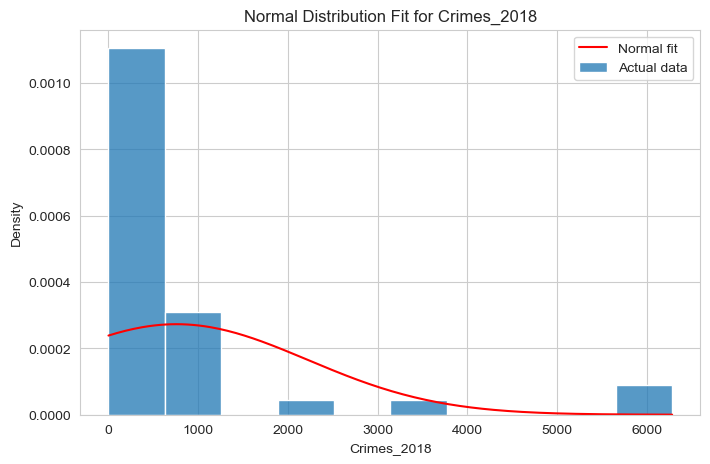

Shapiro-Wilk p-value: 2.329542653845546e-09
The data does NOT follow a normal distribution.


In [21]:
mu, sigma = stats.norm.fit(df["Crimes_2018"])
print("Fitted mean:", round(mu, 2))
print("Fitted std :", round(sigma, 2))

x_values = np.linspace(df["Crimes_2018"].min(), df["Crimes_2018"].max(), 200)
pdf_values = stats.norm.pdf(x_values, mu, sigma)

plt.figure(figsize=(8, 5))
sns.histplot(df["Crimes_2018"], stat="density", bins=10, label="Actual data")
plt.plot(x_values, pdf_values, color="red", label="Normal fit")
plt.title("Normal Distribution Fit for Crimes_2018")
plt.legend()
plt.show()

# Shapiro-Wilk test: a small p-value means the data is NOT normal
stat, p = stats.shapiro(df["Crimes_2018"])
print("Shapiro-Wilk p-value:", p)
if p < 0.05:
    print("The data does NOT follow a normal distribution.")
else:
    print("The data looks approximately normal.")

**Comment:** The normal curve fits poorly because the data is right-skewed (many small values, a few very large ones). So cyber-crime counts are not normally distributed.

### 6.3 Hypothesis testing (two-sample t-test)
**Question:** Is the average number of cyber crimes in 2018 different from 2016?

- H0 (null): the mean cases in 2016 and 2018 are equal.
- H1 (alternative): the means are different.

We use a 5% significance level (0.05).

In [22]:
t_stat, p_value = stats.ttest_ind(df["Crimes_2016"], df["Crimes_2018"])

print("Mean 2016:", round(df["Crimes_2016"].mean(), 2))
print("Mean 2018:", round(df["Crimes_2018"].mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Result: Reject H0. The difference in means is statistically significant.")
else:
    print("Result: Fail to reject H0. The difference in means is NOT statistically significant.")

Mean 2016: 342.14
Mean 2018: 756.89
T-statistic: -1.5555
P-value: 0.1243
Result: Fail to reject H0. The difference in means is NOT statistically significant.


**Comment:** The average did rise from 2016 to 2018, but because the data varies so much between states, the t-test cannot confirm that the rise is statistically significant (p > 0.05).

## 7. Classification
**Goal:** predict whether a State/UT has a *High* cyber-crime rate (1) or *Low* rate (0).

We create the target `High_Rate` = 1 if `Rate_2018` is above the median, else 0.

To avoid "cheating", we do **not** use `Rate_2018`, `Crimes_2018` or `Share_2018` as features, since the rate is calculated directly from them. We use 2016 cases, 2017 cases and population.

In [23]:
median_rate = df["Rate_2018"].median()
df["High_Rate"] = (df["Rate_2018"] > median_rate).astype(int)

print("Median rate:", median_rate)
print(df["High_Rate"].value_counts())

X = df[["Crimes_2016", "Crimes_2017", "Population_Lakhs"]]
Y = df["High_Rate"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=42, stratify=Y)

print("\nTrain size:", X_train.shape[0], " Test size:", X_test.shape[0])

Median rate: 1.0
High_Rate
0    20
1    16
Name: count, dtype: int64

Train size: 25  Test size: 11


### Model 1: Logistic Regression
Logistic Regression works better when features are on a similar scale, so we standardise them first.

In [24]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, Y_train)
log_pred = log_model.predict(X_test_scaled)

print("Logistic Regression")
print("Accuracy:", round(accuracy_score(Y_test, log_pred), 3))
print("F1-score:", round(f1_score(Y_test, log_pred), 3))

Logistic Regression
Accuracy: 0.818
F1-score: 0.75


### Model 2: Decision Tree
Trees don't need scaling. We limit the depth to 3 so the tree doesn't just memorise the small dataset.

In [25]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, Y_train)
tree_pred = tree_model.predict(X_test)

print("Decision Tree")
print("Accuracy:", round(accuracy_score(Y_test, tree_pred), 3))
print("F1-score:", round(f1_score(Y_test, tree_pred), 3))

Decision Tree
Accuracy: 0.818
F1-score: 0.8


### Confusion matrices
Rows = actual class, columns = predicted class. The diagonal shows correct predictions.

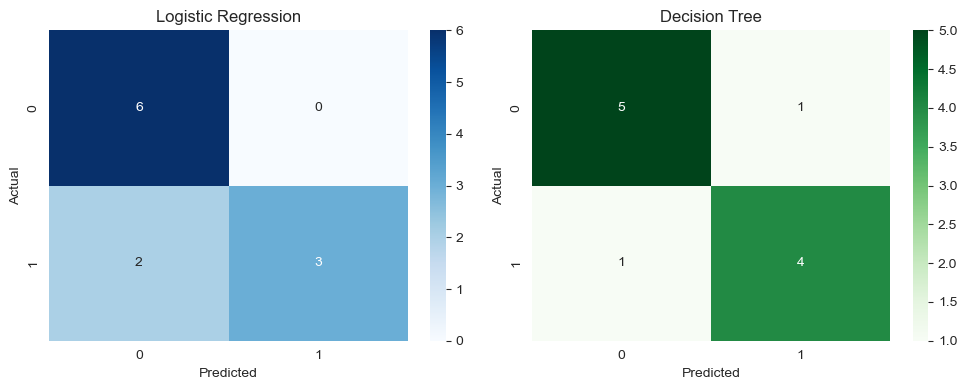

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(confusion_matrix(Y_test, log_pred), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(confusion_matrix(Y_test, tree_pred), annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [27]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_score(Y_test, log_pred), accuracy_score(Y_test, tree_pred)],
    "F1-Score": [f1_score(Y_test, log_pred), f1_score(Y_test, tree_pred)]
})
display(results)

,Model,Accuracy,F1-Score
0,Logistic Regression,0.818182,0.75
1,Decision Tree,0.818182,0.80


**Note:** The dataset has only 36 rows, so the test set is tiny (about 11 rows). One wrong prediction changes the accuracy a lot, so treat these scores as a demonstration rather than a reliable measure.

## 8. Regression
**Goal:** predict the number of cyber crimes in 2018 (`Crimes_2018`) using 2016 cases, 2017 cases and population.

In [28]:
X_reg = df[["Crimes_2016", "Crimes_2017", "Population_Lakhs"]]
Y_reg = df["Crimes_2018"]

Xr_train, Xr_test, Yr_train, Yr_test = train_test_split(
    X_reg, Y_reg, test_size=0.3, random_state=42)

print("Train size:", Xr_train.shape[0], " Test size:", Xr_test.shape[0])

Train size: 25  Test size: 11


### Model 1: Linear Regression

In [29]:
lin_model = LinearRegression()
lin_model.fit(Xr_train, Yr_train)
lin_pred = lin_model.predict(Xr_test)

print("Linear Regression")
print("MAE:", round(mean_absolute_error(Yr_test, lin_pred), 2))
print("MSE:", round(mean_squared_error(Yr_test, lin_pred), 2))
print("R2 :", round(r2_score(Yr_test, lin_pred), 3))

Linear Regression
MAE: 71.05
MSE: 13955.75
R2 : 0.996


### Model 2: Random Forest Regressor
A random forest averages many decision trees.

In [30]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(Xr_train, Yr_train)
rf_pred = rf_model.predict(Xr_test)

print("Random Forest Regressor")
print("MAE:", round(mean_absolute_error(Yr_test, rf_pred), 2))
print("MSE:", round(mean_squared_error(Yr_test, rf_pred), 2))
print("R2 :", round(r2_score(Yr_test, rf_pred), 3))

Random Forest Regressor
MAE: 421.01
MSE: 805562.74
R2 : 0.742


### Compare the two models
Lower MAE/MSE is better. R² closer to 1 is better.

,Model,MAE,MSE,R2
0,Linear Regression,71.047323,13955.753967,0.995539
1,Random Forest,421.014545,805562.737582,0.742472


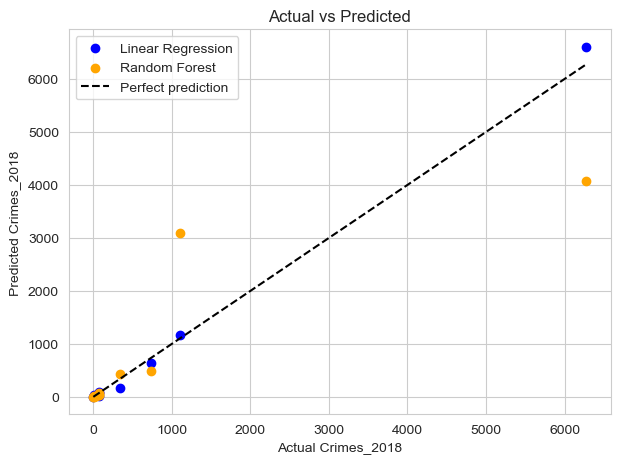

In [31]:
reg_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mean_absolute_error(Yr_test, lin_pred), mean_absolute_error(Yr_test, rf_pred)],
    "MSE": [mean_squared_error(Yr_test, lin_pred), mean_squared_error(Yr_test, rf_pred)],
    "R2": [r2_score(Yr_test, lin_pred), r2_score(Yr_test, rf_pred)]
})
display(reg_results)

# Actual vs predicted plot
plt.figure(figsize=(7, 5))
plt.scatter(Yr_test, lin_pred, label="Linear Regression", color="blue")
plt.scatter(Yr_test, rf_pred, label="Random Forest", color="orange")
plt.plot([Yr_test.min(), Yr_test.max()], [Yr_test.min(), Yr_test.max()], "k--", label="Perfect prediction")
plt.xlabel("Actual Crimes_2018")
plt.ylabel("Predicted Crimes_2018")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

## Conclusion
- Cyber-crime cases rose sharply from 2016 to 2018 (All-India total: 12,317 → 27,248).
- A few states (Karnataka, Uttar Pradesh) are clear outliers, and the data is right-skewed, not normal.
- Previous-year counts are strong predictors of the next year's count, so Linear Regression performs very well here.
- With only 36 rows, results can change a lot with a different train/test split.